# Simulations: AR(1) vs MA(1) Dynamics & Machine Learning Lag Sensitivity

This notebook evaluates the structural asymmetry between pure autoregressive memory and pure moving average memory:
1. **Stationary AR(1)**: $y_t = 0.8 y_{t-1} + \varepsilon_t, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, 1)$
2. **Invertible MA(1)**: $y_t = \varepsilon_t + 0.8 \varepsilon_{t-1}, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, 1)$

### Experimental Design
Both processes are evaluated across multi-step forecast horizons $h \in [1, 3, 7, 14, 30]$ over 100 Monte Carlo replications ($T=2542, N_{\text{test}}=364$).

We compare:
- **ARMA(1,1)**: linear benchmark estimated via exact maximum likelihood.
- **Random Forest (1 lag)**: $X_t = [y_{t-1}]$.
- **Random Forest (4 lags)**: $X_t = [y_{t-1}, y_{t-2}, y_{t-3}, y_{t-4}]$.
- **Random Forest (10 lags)**: $X_t = [y_{t-1}, \dots, y_{t-10}]$.

### Core Research Question
Does increasing the number of lag features have symmetric effects on AR and MA processes?
- In **AR(1)**, the Markov property implies that $y_{t-1}$ contains the entire predictable signal. Extra lags only provide geometric diagonal smoothing at $h=1$, but accumulate recursive error at larger horizons.
- In **MA(1)**, the unobserved innovation $\varepsilon_{t-1}$ requires an infinite autoregressive representation $AR(\infty) = \sum_{j=1}^\infty (-0.8)^j y_{t-j}$. Single-lag models are severely misspecified, and adding lags substantially improves predictive accuracy.

## 1. Setup and Parameters

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Universal modular simulation engine and DGPs
from src.simulations import (
    generate_ar1,
    generate_ma1,
    model_arma_multistep,
    model_rf_levels_multistep,
    run_simulation_multistep,
)

FIG_DIR = Path("figures/simulations")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("../Results/Simulations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Simulation parameters
N_SAMPLES = 2542
N_TEST = 364
N_SIM = 100
SIGMA = 1.0
PHI = 0.8
THETA = 0.8
BASE_SEED = 42
HORIZONS = [1, 3, 7, 14, 30]


## 2. Monte Carlo Simulation Execution (AR(1) and MA(1))

In [2]:
ar_csv = RESULTS_DIR / "ar1_results_100.csv"
ma_csv = RESULTS_DIR / "ma1_results_100.csv"

models = {
    "arma11": model_arma_multistep(order=(1, 0, 1), trend="n", maxiter=200),
    "rf_1lag": model_rf_levels_multistep(lags=[1], n_estimators=100),
    "rf_4lags": model_rf_levels_multistep(lags=list(range(1, 5)), n_estimators=100),
    "rf_10lags": model_rf_levels_multistep(lags=list(range(1, 11)), n_estimators=100),
}

if ar_csv.exists() and ma_csv.exists():
    print(f"Loading existing AR(1) results from {ar_csv}...")
    df_ar = pd.read_csv(ar_csv)
    print(f"Loading existing MA(1) results from {ma_csv}...")
    df_ma = pd.read_csv(ma_csv)
else:
    # 1. Execute AR(1) Simulation
    print(f"Executing {N_SIM} Monte Carlo replications for AR(1) (phi={PHI}) across horizons {HORIZONS}...")
    df_ar = run_simulation_multistep(
        dgp_fn=generate_ar1,
        models=models,
        n_sim=N_SIM,
        n_samples=N_SAMPLES,
        n_test=N_TEST,
        horizons=HORIZONS,
        phi=PHI,
        sigma=SIGMA,
        base_seed=BASE_SEED,
        n_jobs=-1,
    )
    df_ar.to_csv(ar_csv, index=False)
    print(f"AR(1) results saved to: {ar_csv}")

    # 2. Execute MA(1) Simulation
    print(f"\nExecuting {N_SIM} Monte Carlo replications for MA(1) (theta={THETA}) across horizons {HORIZONS}...")
    df_ma = run_simulation_multistep(
        dgp_fn=generate_ma1,
        models=models,
        n_sim=N_SIM,
        n_samples=N_SAMPLES,
        n_test=N_TEST,
        horizons=HORIZONS,
        theta=THETA,
        sigma=SIGMA,
        base_seed=BASE_SEED,
        n_jobs=-1,
    )
    df_ma.to_csv(ma_csv, index=False)
    print(f"MA(1) results saved to: {ma_csv}")


Loading existing AR(1) results from ../Results/Simulations/ar1_results_100.csv...
Loading existing MA(1) results from ../Results/Simulations/ma1_results_100.csv...


## 3. Summary Statistics and Model Comparison

In [3]:
models_list = [
    ("ARMA(1,1) Benchmark", "arma11"),
    ("Random Forest (1 lag)", "rf_1lag"),
    ("Random Forest (4 lags)", "rf_4lags"),
    ("Random Forest (10 lags)", "rf_10lags"),
]

def create_summary_table(df_res, dgp_name):
    rows = []
    for h in HORIZONS:
        arma_mean = df_res[f"rmse_arma11_h{h}"].mean()
        for label, m_key in models_list:
            r_col = f"rmse_{m_key}_h{h}"
            m_col = f"mae_{m_key}_h{h}"
            rmse_mean = df_res[r_col].mean()
            mae_mean = df_res[m_col].mean()
            penalty = ((rmse_mean - arma_mean) / arma_mean) * 100
            rows.append({
                "Horizon": f"h={h}",
                "Model": label,
                "RMSE Mean": rmse_mean,
                "RMSE Std": df_res[r_col].std(),
                "MAE Mean": mae_mean,
                "MAE Std": df_res[m_col].std(),
                "Penalty vs ARMA (%)": penalty,
            })
    df_sum = pd.DataFrame(rows)
    print(f"=== Performance Summary across 100 Replications: {dgp_name} ===")
    display(df_sum.round(4))
    pivot = df_sum.pivot(index="Model", columns="Horizon", values="RMSE Mean")[
        [f"h={h}" for h in HORIZONS]
    ]
    print(f"\n=== {dgp_name} Mean RMSE Pivot Table ===")
    display(pivot.round(4))
    return df_sum, pivot

sum_ar, pivot_ar = create_summary_table(df_ar, "AR(1) (phi=0.8)")
sum_ma, pivot_ma = create_summary_table(df_ma, "MA(1) (theta=0.8)")

# ARMA(1,1) Parameter Estimates
print("\n=== ARMA(1,1) Parameter Estimates on AR(1) ===")
print(f"phi_1: {df_ar['phi_1'].mean():.4f} +/- {df_ar['phi_1'].std():.4f}")
print(f"theta_1: {df_ar['theta_1'].mean():.4f} +/- {df_ar['theta_1'].std():.4f}")

print("\n=== ARMA(1,1) Parameter Estimates on MA(1) ===")
print(f"phi_1: {df_ma['phi_1'].mean():.4f} +/- {df_ma['phi_1'].std():.4f}")
print(f"theta_1: {df_ma['theta_1'].mean():.4f} +/- {df_ma['theta_1'].std():.4f}")


=== Performance Summary across 100 Replications: AR(1) (phi=0.8) ===


,Horizon,Model,RMSE Mean,RMSE Std,MAE Mean,MAE Std,Penalty vs ARMA (%)
0,h=1,"ARMA(1,1) Benchmark",0.9967,0.0383,0.7966,0.0339,0.0000
1,h=1,Random Forest (1 lag),1.2157,0.0435,0.9714,0.0390,21.9791
2,h=1,Random Forest (4 lags),1.0600,0.0396,0.8490,0.0342,6.3597
3,h=1,Random Forest (10 lags),1.0417,0.0402,0.8324,0.0345,4.5153
4,h=3,"ARMA(1,1) Benchmark",1.4180,0.0720,1.1324,0.0609,0.0000
5,h=3,Random Forest (1 lag),1.7200,0.0792,1.3736,0.0652,21.3013
6,h=3,Random Forest (4 lags),1.5022,0.0747,1.1984,0.0602,5.9400
7,h=3,Random Forest (10 lags),1.4828,0.0765,1.1830,0.0657,4.5710
8,h=7,"ARMA(1,1) Benchmark",1.6133,0.1138,1.2903,0.0935,0.0000
9,h=7,Random Forest (1 lag),1.9620,0.1103,1.5656,0.0876,21.6118



=== AR(1) (phi=0.8) Mean RMSE Pivot Table ===


Horizon,h=1,h=3,h=7,h=14,h=30
Model,,,,,
"ARMA(1,1) Benchmark",0.9967,1.4180,1.6133,1.6502,1.6522
Random Forest (1 lag),1.2157,1.7200,1.9620,2.0207,2.0286
Random Forest (10 lags),1.0417,1.4828,1.6856,1.7449,1.7636
Random Forest (4 lags),1.0600,1.5022,1.7090,1.7521,1.7586


=== Performance Summary across 100 Replications: MA(1) (theta=0.8) ===


,Horizon,Model,RMSE Mean,RMSE Std,MAE Mean,MAE Std,Penalty vs ARMA (%)
0,h=1,"ARMA(1,1) Benchmark",0.9965,0.0384,0.7962,0.0340,0.0000
1,h=1,Random Forest (1 lag),1.3510,0.0586,1.0808,0.0498,35.5674
2,h=1,Random Forest (4 lags),1.0851,0.0432,0.8658,0.0381,8.8910
3,h=1,Random Forest (10 lags),1.0712,0.0427,0.8545,0.0366,7.4931
4,h=3,"ARMA(1,1) Benchmark",1.2712,0.0580,1.0159,0.0498,0.0000
5,h=3,Random Forest (1 lag),1.5430,0.0653,1.2324,0.0560,21.3826
6,h=3,Random Forest (4 lags),1.3426,0.0626,1.0752,0.0539,5.6151
7,h=3,Random Forest (10 lags),1.3188,0.0602,1.0548,0.0520,3.7477
8,h=7,"ARMA(1,1) Benchmark",1.2712,0.0580,1.0159,0.0498,0.0000
9,h=7,Random Forest (1 lag),1.5385,0.0711,1.2311,0.0580,21.0306



=== MA(1) (theta=0.8) Mean RMSE Pivot Table ===


Horizon,h=1,h=3,h=7,h=14,h=30
Model,,,,,
"ARMA(1,1) Benchmark",0.9965,1.2712,1.2712,1.2712,1.2712
Random Forest (1 lag),1.3510,1.5430,1.5385,1.5492,1.5379
Random Forest (10 lags),1.0712,1.3188,1.3133,1.3078,1.3061
Random Forest (4 lags),1.0851,1.3426,1.3297,1.3319,1.3278



=== ARMA(1,1) Parameter Estimates on AR(1) ===
phi_1: 0.7986 +/- 0.0184
theta_1: 0.0015 +/- 0.0276

=== ARMA(1,1) Parameter Estimates on MA(1) ===
phi_1: -0.0004 +/- 0.0271
theta_1: 0.8013 +/- 0.0180


## 4. Visualizations: Lag Sensitivity Contrast & Multi-Step Horizons

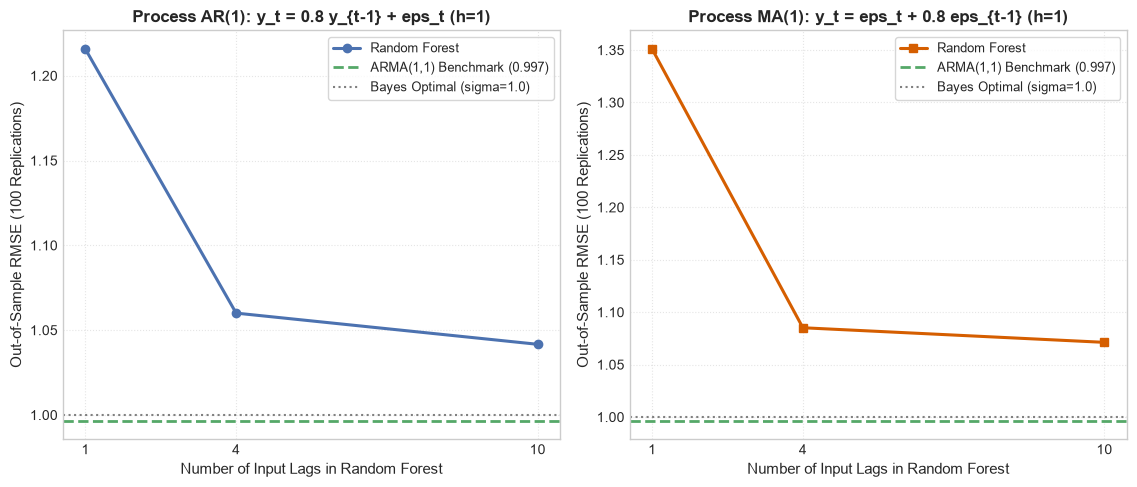

Saved: figures/simulations/ar_ma_lag_comparison.png


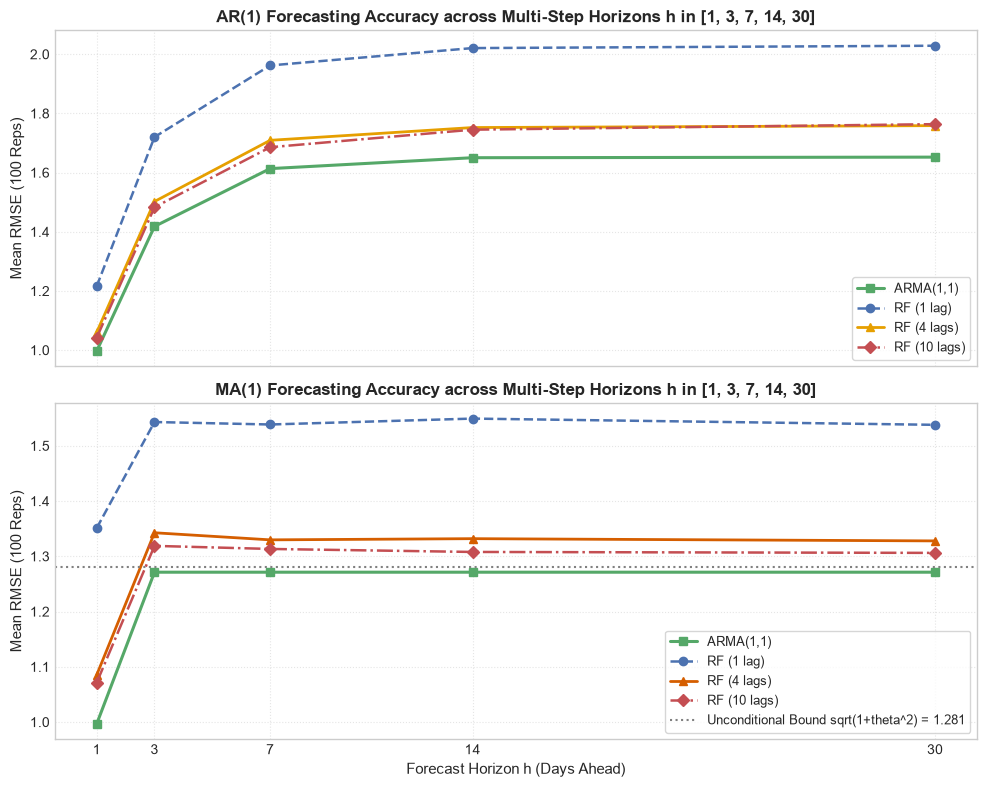

Saved: figures/simulations/ar_ma_multistep_rmse.png


In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 13,
    "grid.alpha": 0.5,
    "grid.linestyle": ":",
})

# 1. Figure 1: Lag Sensitivity Contrast (AR(1) vs MA(1) at h=1)
fig1, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(11.5, 5.0), sharey=False)

lag_nums = [1, 4, 10]
ar_rf_means = [df_ar["rmse_rf_1lag_h1"].mean(), df_ar["rmse_rf_4lags_h1"].mean(), df_ar["rmse_rf_10lags_h1"].mean()]
ar_arma_mean = df_ar["rmse_arma11_h1"].mean()

ma_rf_means = [df_ma["rmse_rf_1lag_h1"].mean(), df_ma["rmse_rf_4lags_h1"].mean(), df_ma["rmse_rf_10lags_h1"].mean()]
ma_arma_mean = df_ma["rmse_arma11_h1"].mean()

# Left: AR(1)
ax_left.plot(lag_nums, ar_rf_means, marker="o", color="#4C72B0", linewidth=2.2, label="Random Forest")
ax_left.axhline(ar_arma_mean, color="#55A868", linestyle="--", linewidth=2.0, label=f"ARMA(1,1) Benchmark ({ar_arma_mean:.3f})")
ax_left.axhline(1.0, color="gray", linestyle=":", linewidth=1.5, label="Bayes Optimal (sigma=1.0)")
ax_left.set_title("Process AR(1): y_t = 0.8 y_{t-1} + eps_t (h=1)")
ax_left.set_xlabel("Number of Input Lags in Random Forest")
ax_left.set_ylabel("Out-of-Sample RMSE (100 Replications)")
ax_left.set_xticks(lag_nums)
ax_left.legend(loc="upper right", frameon=True, fontsize=9.5)

# Right: MA(1)
ax_right.plot(lag_nums, ma_rf_means, marker="s", color="#D55E00", linewidth=2.2, label="Random Forest")
ax_right.axhline(ma_arma_mean, color="#55A868", linestyle="--", linewidth=2.0, label=f"ARMA(1,1) Benchmark ({ma_arma_mean:.3f})")
ax_right.axhline(1.0, color="gray", linestyle=":", linewidth=1.5, label="Bayes Optimal (sigma=1.0)")
ax_right.set_title("Process MA(1): y_t = eps_t + 0.8 eps_{t-1} (h=1)")
ax_right.set_xlabel("Number of Input Lags in Random Forest")
ax_right.set_ylabel("Out-of-Sample RMSE (100 Replications)")
ax_right.set_xticks(lag_nums)
ax_right.legend(loc="upper right", frameon=True, fontsize=9.5)

plt.tight_layout()
fig1_path = FIG_DIR / "ar_ma_lag_comparison.png"
fig1.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

# 2. Figure 2: Multi-Horizon Forecasting Evolution (AR vs MA across h)
fig2, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10.0, 8.0), sharex=True)

h_vals = HORIZONS
ax_top.plot(h_vals, [df_ar[f"rmse_arma11_h{h}"].mean() for h in h_vals], marker="s", color="#55A868", linewidth=2.2, label="ARMA(1,1)")
ax_top.plot(h_vals, [df_ar[f"rmse_rf_1lag_h{h}"].mean() for h in h_vals], marker="o", color="#4C72B0", linestyle="--", linewidth=1.8, label="RF (1 lag)")
ax_top.plot(h_vals, [df_ar[f"rmse_rf_4lags_h{h}"].mean() for h in h_vals], marker="^", color="#E69F00", linewidth=2.0, label="RF (4 lags)")
ax_top.plot(h_vals, [df_ar[f"rmse_rf_10lags_h{h}"].mean() for h in h_vals], marker="D", color="#C44E52", linestyle="-.", linewidth=1.8, label="RF (10 lags)")
ax_top.set_title("AR(1) Forecasting Accuracy across Multi-Step Horizons h in [1, 3, 7, 14, 30]")
ax_top.set_ylabel("Mean RMSE (100 Reps)")
ax_top.legend(loc="lower right", frameon=True, fontsize=9.5)

ax_bot.plot(h_vals, [df_ma[f"rmse_arma11_h{h}"].mean() for h in h_vals], marker="s", color="#55A868", linewidth=2.2, label="ARMA(1,1)")
ax_bot.plot(h_vals, [df_ma[f"rmse_rf_1lag_h{h}"].mean() for h in h_vals], marker="o", color="#4C72B0", linestyle="--", linewidth=1.8, label="RF (1 lag)")
ax_bot.plot(h_vals, [df_ma[f"rmse_rf_4lags_h{h}"].mean() for h in h_vals], marker="^", color="#D55E00", linewidth=2.0, label="RF (4 lags)")
ax_bot.plot(h_vals, [df_ma[f"rmse_rf_10lags_h{h}"].mean() for h in h_vals], marker="D", color="#C44E52", linestyle="-.", linewidth=1.8, label="RF (10 lags)")
ax_bot.axhline(np.sqrt(1 + 0.8**2), color="gray", linestyle=":", linewidth=1.5, label="Unconditional Bound sqrt(1+theta^2) = 1.281")
ax_bot.set_title("MA(1) Forecasting Accuracy across Multi-Step Horizons h in [1, 3, 7, 14, 30]")
ax_bot.set_xlabel("Forecast Horizon h (Days Ahead)")
ax_bot.set_ylabel("Mean RMSE (100 Reps)")
ax_bot.set_xticks(h_vals)
ax_bot.legend(loc="lower right", frameon=True, fontsize=9.5)

plt.tight_layout()
fig2_path = FIG_DIR / "ar_ma_multistep_rmse.png"
fig2.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")
